In [34]:
import pandas as pd

X_train = pd.read_csv('X_train.csv')
X_val   = pd.read_csv('X_val.csv')
X_test  = pd.read_csv('X_test.csv')
y_train = pd.read_csv('y_train.csv').squeeze()
y_val   = pd.read_csv('y_val.csv').squeeze()
y_test  = pd.read_csv('y_test.csv').squeeze()

print(X_train.shape, X_val.shape, X_test.shape)

(67289, 8) (14419, 8) (14420, 8)


In [35]:
# ── CELL: Imports ────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
 
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
 
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
 
print("TF version:", tf.__version__)

TF version: 2.20.0


In [36]:
# ── CELL: Scale features ──────────────────────────────────────
# Must fit ONLY on training data, then apply to val & test
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)
 
 
# ── CELL: Class weights (handles 91/9 imbalance from EDA) ────
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights:", class_weight_dict)
# Expect ~{0: 0.55, 1: 5.5} — penalises missing diabetic cases more

Class weights: {0: np.float64(0.5483847307341244), 1: np.float64(5.666919319521644)}


In [37]:
# ── CELL: Input layer ─────────────────────────────────────────
input_layer = keras.Input(shape=(X_train.shape[1],), name='input_layer')
 
 
# ── CELL: Hidden layers ───────────────────────────────────────
x = layers.Dense(64, name='hidden_1')(input_layer)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)
x = layers.Dropout(0.3)(x)
 
x = layers.Dense(32, name='hidden_2')(x)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)
x = layers.Dropout(0.3)(x)

In [38]:
# ── CELL: Output layer ────────────────────────────────────────
output_layer = layers.Dense(1, activation='sigmoid', name='output_layer')(x)
 
model = keras.Model(inputs=input_layer, outputs=output_layer, name='diabetes_ann')
 
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='auc'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall')
    ]
)
 
model.summary()

Model: "diabetes_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,073 (12.00 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 192 (768.00 B)

In [39]:
# ── CELL: Train model ─────────────────────────────────────────
cb_early_stop = callbacks.EarlyStopping(
    monitor='val_auc', patience=10,
    restore_best_weights=True, mode='max'
)
cb_reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5,
    patience=5, min_lr=1e-6, verbose=1
)
 
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=512,
    class_weight=class_weight_dict,
    callbacks=[cb_early_stop, cb_reduce_lr],
    verbose=1
)
 

Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7172 - auc: 0.8856 - loss: 0.4403 - precision: 0.2202 - recall: 0.8676 - val_accuracy: 0.8274 - val_auc: 0.9544 - val_loss: 0.3953 - val_precision: 0.3300 - val_recall: 0.9277 - learning_rate: 0.0010
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8517 - auc: 0.9469 - loss: 0.2995 - precision: 0.3612 - recall: 0.8860 - val_accuracy: 0.8420 - val_auc: 0.9577 - val_loss: 0.3250 - val_precision: 0.3494 - val_recall: 0.9175 - learning_rate: 0.0010
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8649 - auc: 0.9544 - loss: 0.2735 - precision: 0.3851 - recall: 0.8902 - val_accuracy: 0.8519 - val_auc: 0.9591 - val_loss: 0.2957 - val_precision: 0.3641 - val_recall: 0.9088 - learning_rate: 0.0010
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8696 - auc: 0.9572 - loss: 0.2636 - precision: 0.3946 - recall: 0.8957 - val_accuracy: 0.8573 - val_auc: 0.9604 - val_loss: 0.2798 -

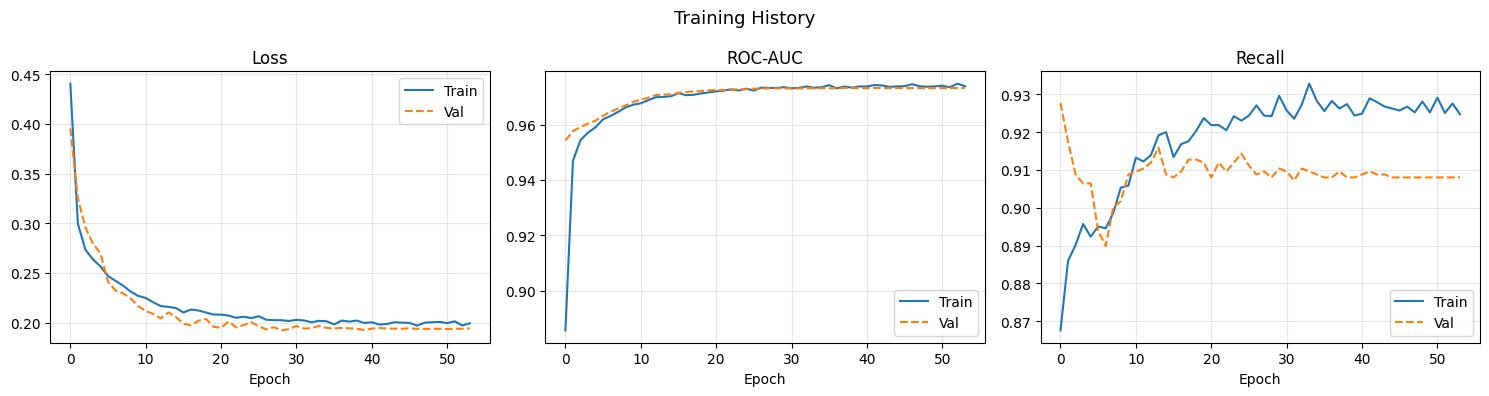

In [40]:
# ── CELL: Plot training curves ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Training History', fontsize=13)
 
for ax, (m, title) in zip(axes, [
    ('loss',   'Loss'),
    ('auc',    'ROC-AUC'),
    ('recall', 'Recall')
]):
    ax.plot(history.history[m],          label='Train', linewidth=1.5)
    ax.plot(history.history[f'val_{m}'], label='Val',   linewidth=1.5, linestyle='--')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(alpha=0.3)
 
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:

THRESHOLD = 0.05
 
y_proba = model.predict(X_test, verbose=0).flatten()
y_pred  = (y_proba >= THRESHOLD).astype(int)
 
print("=" * 55)
print(f"  TEST SET EVALUATION  (threshold = {THRESHOLD})")
print("=" * 55)
print(classification_report(
    y_test, y_pred,
    target_names=['Non-Diabetic', 'Diabetic'],
    digits=4
))
 
metrics_summary = {
    'Accuracy' : accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall'   : recall_score(y_test, y_pred),
    'F1-Score' : f1_score(y_test, y_pred),
    'ROC-AUC'  : roc_auc_score(y_test, y_proba),
}
for k, v in metrics_summary.items():
    print(f"  {k:<12}: {v:.4f}")

  TEST SET EVALUATION  (threshold = 0.05)
              precision    recall  f1-score   support

Non-Diabetic     0.9997    0.6656    0.7991     13147
    Diabetic     0.2241    0.9976    0.3660      1273

    accuracy                         0.6949     14420
   macro avg     0.6119    0.8316    0.5826     14420
weighted avg     0.9312    0.6949    0.7609     14420

  Accuracy    : 0.6949
  Precision   : 0.2241
  Recall      : 0.9976
  F1-Score    : 0.3660
  ROC-AUC     : 0.9738


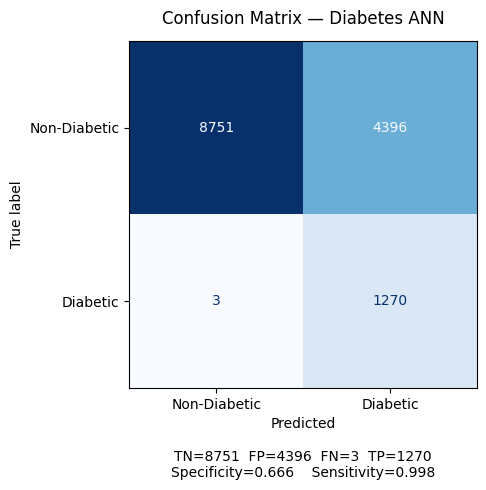

In [44]:
# — CELL: Confusion matrix —
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Non-Diabetic', 'Diabetic']).plot(
    ax=ax, colorbar=False, cmap='Blues',
    values_format='d'   # ← add this
)
ax.set_title('Confusion Matrix — Diabetes ANN', pad=12)
ax.set_xlabel(
    f'Predicted\n\n'
    f'TN={tn}  FP={fp}  FN={fn}  TP={tp}\n'
    f'Specificity={tn/(tn+fp):.3f}    Sensitivity={tp/(tp+fn):.3f}'
)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()